In [4]:
import os
import uuid
import cv2
import torch
import numpy as np
from PIL import Image
from tqdm import tqdm
import matplotlib.pyplot as plt

from torchvision.ops import nms
from sklearn.decomposition import PCA
import hdbscan
import open_clip
from ultralytics import YOLO


In [5]:
import os
import cv2
import torch
import hdbscan
import numpy as np
import matplotlib.pyplot as plt

from PIL import Image
from collections import defaultdict
from IPython.display import display
import ipywidgets as widgets


In [6]:
# ------------------
# Config
# ------------------
YOLO_MODEL_A = "models/benthic_object_detector.pt"
YOLO_MODEL_B = "models/midwater_object_detector.pt"
VIDEO_PATH = "ray_video.mp4"
FRAME_STRIDE_SECONDS = 0.5
ROI_DIR = "rois"
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
CLIP_CHECKPOINT = "open_clip_pytorch_model_bioclip2.bin"
CONF_THRESHOLD = 0.01   # as low as YOLO allows reliably
IOU_THRESHOLD = 0.9     # very permissive NMS inside YOLO
NMS_IOU_THRESH = 0.5
MIN_BOX_AREA = 32 * 32
OUTPUT_DIR = "embeddings"
MAX_PER_CLUSTER = 5
os.makedirs(ROI_DIR, exist_ok=True)


In [7]:
# ------------------
# Load YOLO models
# ------------------
yolo_model_1 = YOLO(YOLO_MODEL_A)
yolo_model_2 = YOLO(YOLO_MODEL_B)



In [8]:
# ------------------
# Load CLIP
# ------------------
clip_model, _, clip_preprocess = open_clip.create_model_and_transforms('hf-hub:imageomics/bioclip-2')
tokenizer = open_clip.get_tokenizer('hf-hub:imageomics/bioclip-2')
clip_model = clip_model.to(DEVICE).eval()


In [9]:
# =========================
# VIDEO FRAME SAMPLER
# =========================
def sample_video_frames(video_path, every_seconds):
    cap = cv2.VideoCapture(video_path)
    fps = cap.get(cv2.CAP_PROP_FPS)
    stride = int(fps * every_seconds)

    frame_idx = 0
    sample_idx = 0

    while True:
        ret, frame = cap.read()
        if not ret:
            break

        if frame_idx % stride == 0:
            rgb = cv2.cvtColor(frame, cv2.COLOR_BGR2RGB)
            yield sample_idx, Image.fromarray(rgb)
            sample_idx += 1

        frame_idx += 1

    cap.release()


In [10]:
# =========================
# EMBEDDING FUNCTION
# =========================
def embed_images(images):
    if not images:
        return np.empty((0, 512))

    with torch.no_grad():
        batch = torch.stack([clip_preprocess(img) for img in images]).to(DEVICE)
        feats = clip_model.encode_image(batch)
        feats = feats / feats.norm(dim=-1, keepdim=True)

    return feats.cpu().numpy()


In [26]:
# =========================
# MAIN PIPELINE
# =========================
all_roi_images = []
all_roi_paths = []
all_roi_records = []
print("Processing video...")

for frame_id, image in tqdm(
    sample_video_frames(VIDEO_PATH, FRAME_STRIDE_SECONDS),
    desc="Frames"
):
    r1 = yolo_model_1(image, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD)[0]
    r2 = yolo_model_2(image, conf=CONF_THRESHOLD, iou=IOU_THRESHOLD)[0]

    if len(r1.boxes) == 0 and len(r2.boxes) == 0:
        continue

    boxes = torch.cat([
        r1.boxes.xyxy.cpu() if len(r1.boxes) else torch.empty((0,4)),
        r2.boxes.xyxy.cpu() if len(r2.boxes) else torch.empty((0,4))
    ])

    scores = torch.cat([
        r1.boxes.conf.cpu() if len(r1.boxes) else torch.empty((0,)),
        r2.boxes.conf.cpu() if len(r2.boxes) else torch.empty((0,))
    ])

    keep = nms(boxes, scores, NMS_IOU_THRESH)
    boxes = boxes[keep]

    for box in boxes:
        x1, y1, x2, y2 = map(int, box.tolist())
        crop = image.crop((x1, y1, x2, y2))

        roi_id = f"{frame_id}_{uuid.uuid4()}"
        path = os.path.join(ROI_DIR, f"{roi_id}.jpg")
        crop.save(path, quality=95)

        all_roi_images.append(crop)
        all_roi_paths.append(path)
        all_roi_records.append({
            "image": crop,
            "path": path,
            "frame_idx": frame_id,
            'bbox': [x1, y1, x2, y2]
        })

print(f"Total ROIs: {len(all_roi_images)}")


Processing video...


Frames: 0it [00:00, ?it/s]


0: 384x640 1 Eels, 1 Rays and Skates, 916.2ms
Speed: 27.7ms preprocess, 916.2ms inference, 20.9ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 2 Eel-likes, 1 Rays and Skates, 786.3ms
Speed: 4.5ms preprocess, 786.3ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)


Frames: 1it [00:01,  1.99s/it]


0: 384x640 1 Eels, 1 Rays and Skates, 529.2ms
Speed: 2.6ms preprocess, 529.2ms inference, 1.1ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 1 Rays and Skates, 554.5ms
Speed: 2.7ms preprocess, 554.5ms inference, 1.3ms postprocess per image at shape (1, 3, 384, 640)


Frames: 2it [00:03,  1.55s/it]

... (129 outputs left out)

Frames: 67it [01:24,  1.20s/it]


0: 384x640 1 Eels, 1 Rays and Skates, 545.2ms
Speed: 2.5ms preprocess, 545.2ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)

0: 384x640 3 Eel-likes, 1 Rays and Skates, 560.5ms
Speed: 2.4ms preprocess, 560.5ms inference, 0.8ms postprocess per image at shape (1, 3, 384, 640)


Frames: 68it [01:25,  1.26s/it]

Total ROIs: 208


In [30]:
# =========================
# EMBED ALL ROIS
# =========================
embeddings = embed_images(all_roi_images)


In [31]:
# =========================
# CLUSTER
# =========================
n_samples, n_features = embeddings.shape
pca_dim = min(50, n_samples, n_features)
embeddings_reduced = PCA(n_components=pca_dim).fit_transform(embeddings)

# -------------------------
# Cluster with HDBSCAN
# -------------------------
clusterer = hdbscan.HDBSCAN(
    min_cluster_size=MAX_PER_CLUSTER,
    metric='euclidean',
    cluster_selection_epsilon=0.00,
    max_cluster_size=100,
    cluster_selection_method='leaf'
)

cluster_labels = clusterer.fit_predict(embeddings)
num_clusters = len(set(cluster_labels)) - (1 if -1 in cluster_labels else 0)
print(f"Found {num_clusters} clusters (excluding noise)")

Found 6 clusters (excluding noise)


In [32]:
for r, lbl in zip(all_roi_records, cluster_labels):
    r["cluster"] = lbl

rois_by_frame = defaultdict(list)
for r in all_roi_records:
    rois_by_frame[r["frame_idx"]].append(r)

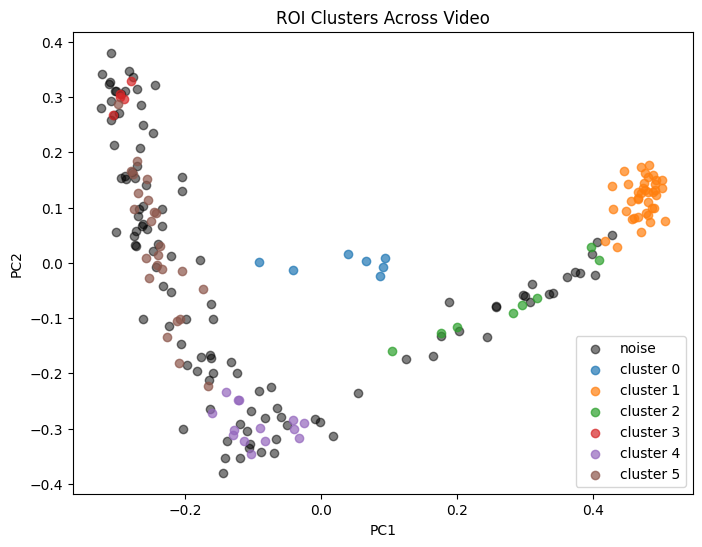

In [33]:
# =========================
# 2D VISUALIZATION
# =========================
embeddings_2d = PCA(n_components=2).fit_transform(embeddings)

plt.figure(figsize=(8,6))
for label in np.unique(cluster_labels):
    pts = embeddings_2d[cluster_labels == label]
    if label == -1:
        plt.scatter(pts[:,0], pts[:,1], c="black", label="noise", alpha=0.5)
    else:
        plt.scatter(pts[:,0], pts[:,1], label=f"cluster {label}", alpha=0.7)

plt.legend()
plt.title("ROI Clusters Across Video")
plt.xlabel("PC1")
plt.ylabel("PC2")
plt.show()


Cluster 1 (39 ROIs)


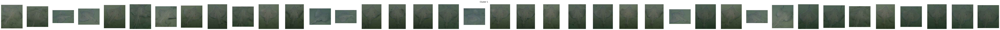


Cluster 4 (14 ROIs)


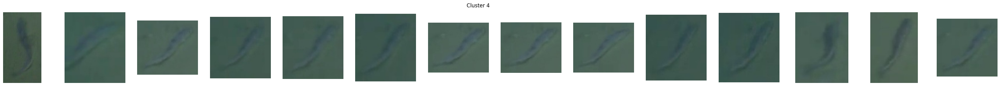


Cluster 5 (24 ROIs)


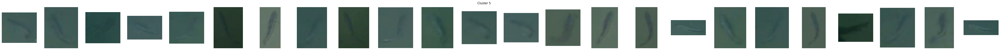


Cluster 3 (5 ROIs)


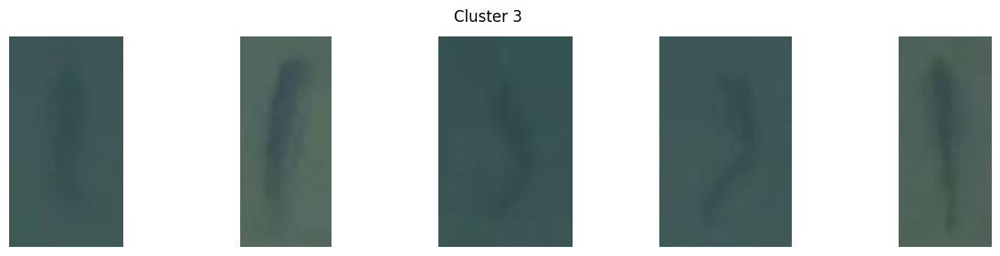


Cluster 0 (7 ROIs)


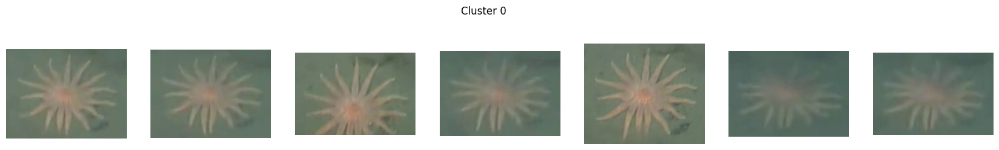


Cluster 2 (8 ROIs)


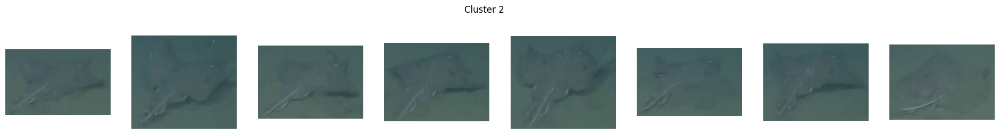


Noise (-1) ROIs: 111





In [34]:
# =========================
# DISPLAY SAMPLE IMAGES
# =========================
import random

clusters = {}
for path, label in zip(all_roi_paths, cluster_labels):
    clusters.setdefault(label, []).append(path)

# -------------------------
# Display clusters
# -------------------------
for label, paths in clusters.items():
    if label == -1:
        continue

    print(f"\nCluster {label} ({len(paths)} ROIs)")
    sample = random.sample(paths, min(100, len(paths)))

    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]

    for ax, p in zip(axes, sample):
        ax.imshow(Image.open(p))
        ax.axis("off")

    plt.suptitle(f"Cluster {label}")
    plt.show()

# -------------------------
# Display noise samples
# -------------------------
if -1 in clusters:
    noise_paths = clusters[-1]
    print(f"\nNoise (-1) ROIs: {len(noise_paths)}")

    sample = random.sample(noise_paths, min(100, len(noise_paths)))

    fig, axes = plt.subplots(1, len(sample), figsize=(3 * len(sample), 3))
    if len(sample) == 1:
        axes = [axes]

    for ax, p in zip(axes, sample):
        ax.imshow(Image.open(p))
        ax.axis("off")

    plt.suptitle("Noise ROIs (unclustered)")
    plt.show()

In [42]:
import plotly.graph_objects as go
from PIL import Image
import base64
from io import BytesIO

In [43]:
def pil_to_base64(path):
    img = Image.open(path).convert("RGB")
    buf = BytesIO()
    img.save(buf, format="PNG")
    return base64.b64encode(buf.getvalue()).decode()


In [44]:
MAX_PER_CLUSTER = 6

# global cluster list
cluster_ids = sorted({r["cluster"] for r in all_roi_records})

# optional: move noise to far right
if -1 in cluster_ids:
    cluster_ids = [c for c in cluster_ids if c != -1] + [-1]

cluster_to_col = {c: i for i, c in enumerate(cluster_ids)}
n_cols = len(cluster_ids)


In [51]:
plotly_frames = []
frame_ids = sorted(rois_by_frame.keys())

for frame_idx in frame_ids:
    images = []
    annotations = []

    # initialize empty columns
    grid = {c: [] for c in cluster_ids}

    for r in rois_by_frame[frame_idx]:
        grid[r["cluster"]].append(r["path"])

    # ---- images ----
    for cluster_id in cluster_ids:
        col = cluster_to_col[cluster_id]
        samples = grid[cluster_id][:MAX_PER_CLUSTER]

        for row, path in enumerate(samples):
            img_b64 = pil_to_base64(path)

            images.append(dict(
                source=f"data:image/png;base64,{img_b64}",
                xref="paper",
                yref="paper",
                x=col / n_cols,
                y=1 - row / MAX_PER_CLUSTER,
                sizex=(1 / n_cols) - 0.01,
                sizey=(1 / MAX_PER_CLUSTER) - 0.02,
                xanchor="left",
                yanchor="top"
            ))

    # ---- column labels ----
    for cluster_id in cluster_ids:
        col = cluster_to_col[cluster_id]

        label = "Noise" if cluster_id == -1 else f"Cluster {cluster_id}"

        annotations.append(dict(
            text=label,
            xref="paper",
            yref="paper",
            x=(col + 0.5) / n_cols,
            y=1.02,
            showarrow=False,
            font=dict(size=14),
            xanchor="center"
        ))

    plotly_frames.append(go.Frame(
        name=str(frame_idx),
        layout=dict(
            images=images,
            annotations=annotations
        )
    ))


In [52]:
fig = go.Figure(
    layout=go.Layout(
        title="ROI Clusters per Frame",
        width=250 * n_cols,
        height=300 + 150 * MAX_PER_CLUSTER,
        images=[],
        annotations=[],
        xaxis=dict(visible=False),
        yaxis=dict(visible=False),
    )
)

fig.frames = plotly_frames

fig.update_layout(
    sliders=[dict(
        active=0,
        currentvalue={"prefix": "Frame: "},
        steps=[dict(
            method="animate",
            label=f.name,
            args=[[f.name], {
                "mode": "immediate",
                "frame": {"duration": 0, "redraw": True},
                "transition": {"duration": 0}
            }]
        ) for f in plotly_frames]
    )]
)


In [40]:
fig.show()


In [54]:
fig.write_html("roi_clusters_columns_by_frame.html", auto_open=True)


In [25]:
fig.update_layout(
    sliders=[dict(
        active=0,
        currentvalue={"prefix": "Frame: "},
        steps=[dict(
            method="animate",
            label=f.name,
            args=[[f.name], {
                "mode": "immediate",
                "frame": {"duration": 0, "redraw": True},
                "transition": {"duration": 0}
            }]
        ) for f in plotly_frames]
    )]
)

fig.show()


In [ ]:
import ipywidgets as widgets
widgets.IntSlider()

In [ ]:
min_frame = min(rois_by_frame.keys())
max_frame = max(rois_by_frame.keys())

slider = widgets.IntSlider(
    value=min_frame,
    min=min_frame,
    max=max_frame,
    step=1,
    description="Frame",
    continuous_update=False
)

widgets.interact(show_frame_clusters, frame_idx=slider)

: 

: 